In [1]:
!pip install -q librosa soundfile scipy matplotlib numpy
!apt-get -qq install -y ffmpeg

Sample Rate: 44100
Duration: 30.0 seconds
Saved: 04/lowpass_500Hz.mp3


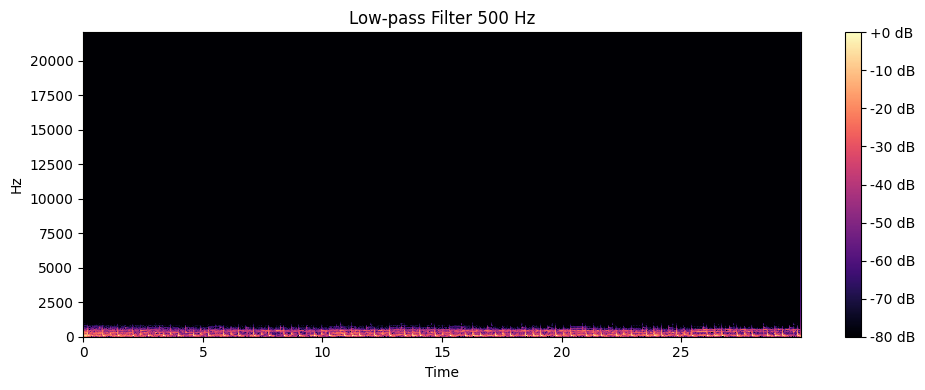

Saved: 04/lowpass_1500Hz.mp3


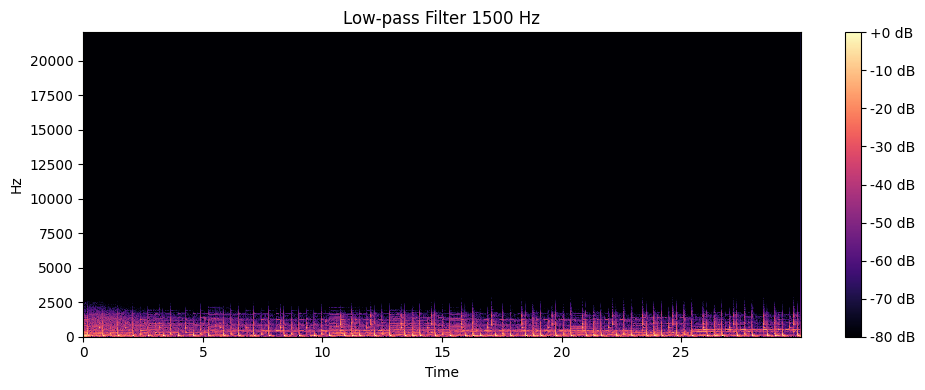

Saved: 04/lowpass_3000Hz.mp3


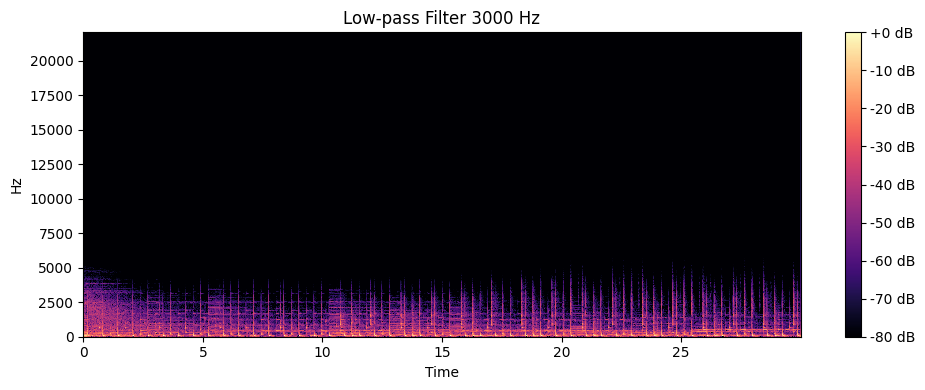

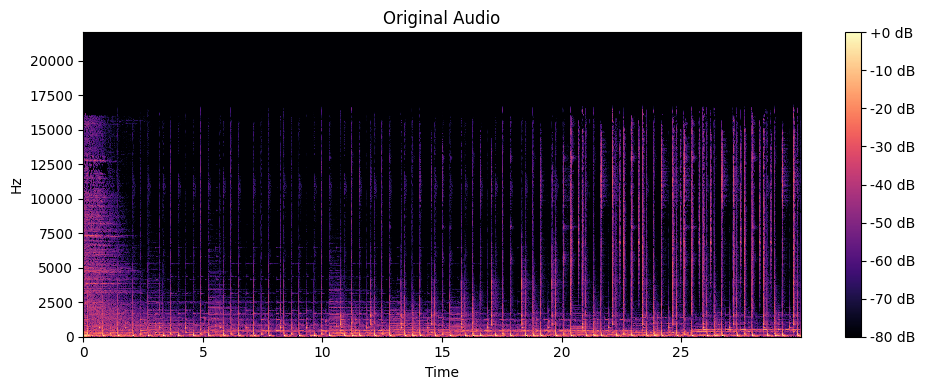

Saved: 04/filtered_vocals.mp3
Saved: 04/estimated_background.mp3


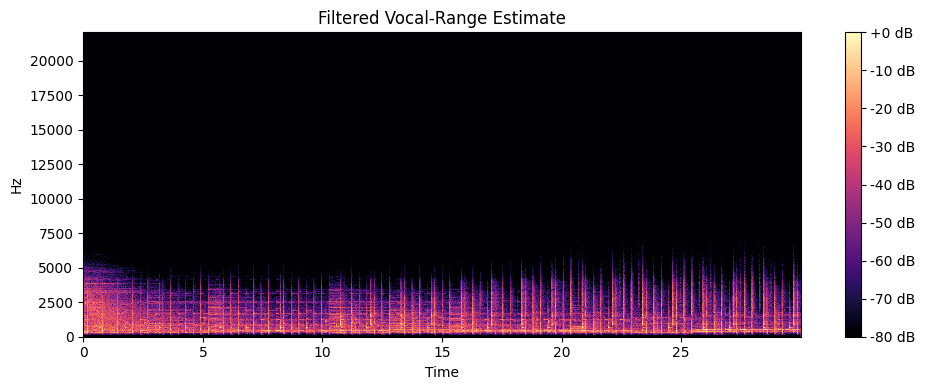

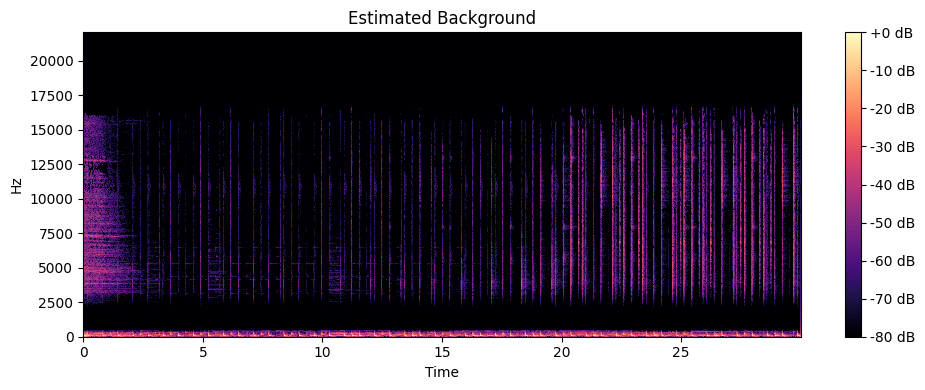

OPE4 completed successfully!


In [10]:

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, sosfiltfilt
import os
import subprocess

# Create output folder
os.makedirs("04", exist_ok=True)

# Load audio file uploaded to Colab
y, sr = librosa.load(filename, sr=None, mono=True)

print("Sample Rate:", sr)
print("Duration:", len(y) / sr, "seconds")

# Low-pass filter
def lowpass(data, cutoff, sr):
    sos = butter(4, cutoff, btype="lowpass",
                 fs=sr, output="sos")
    return sosfiltfilt(sos, data)

# Band-pass filter
def bandpass(data, low, high, sr):
    sos = butter(4, [low, high], btype="bandpass",
                 fs=sr, output="sos")
    return sosfiltfilt(sos, data)

# Save audio as MP3
def save_mp3(data, name):
    wav_file = f"04/{name}.wav"
    mp3_file = f"04/{name}.mp3"

    sf.write(wav_file, data, sr)

    subprocess.run([
        "ffmpeg", "-y", "-i", wav_file,
        "-b:a", "192k", mp3_file
    ], check=True, capture_output=True)

    os.remove(wav_file)
    print("Saved:", mp3_file)

# Display and save spectrogram
def show_spectrogram(data, title, image_name):
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(data)), ref=np.max
    )

    plt.figure(figsize=(10, 4))
    librosa.display.specshow(
        D, sr=sr, x_axis="time", y_axis="hz"
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"04/{image_name}", dpi=150,
                bbox_inches="tight")
    plt.show()

# Q3(a): Low-pass filters
for cutoff in [500, 1500, 3000]:
    if cutoff >= sr / 2:
        print("Skipping cutoff:", cutoff)
        continue

    filtered = lowpass(y, cutoff, sr)

    save_mp3(filtered, f"lowpass_{cutoff}Hz")

    show_spectrogram(
        filtered,
        f"Low-pass Filter {cutoff} Hz",
        f"LPF-{cutoff}.png"
    )

# Original audio spectrogram
show_spectrogram(
    y, "Original Audio", "Original Audio.png"
)

# Q3(b): Vocal-range and background estimates
if 3400 >= sr / 2:
    raise ValueError(
        "Sampling rate is too low for the 3400 Hz cutoff."
    )

vocals = bandpass(y, 300, 3400, sr)
background = y - vocals

save_mp3(vocals, "filtered_vocals")
save_mp3(background, "estimated_background")

show_spectrogram(
    vocals, "Filtered Vocal-Range Estimate",
    "Filtered Vocal.png"
)

show_spectrogram(
    background, "Estimated Background",
    "Estimated Background.png"
)

print("OPE4 completed successfully!")


Listen to the filtered results

In [11]:
from IPython.display import Audio, display

print("Original Audio")
display(Audio(y, rate=sr))

print("Low-pass 500 Hz")
display(Audio(
    librosa.load("04/lowpass_500Hz.mp3", sr=sr)[0],
    rate=sr
))

print("Low-pass 1500 Hz")
display(Audio(
    librosa.load("04/lowpass_1500Hz.mp3", sr=sr)[0],
    rate=sr
))

print("Low-pass 3000 Hz")
display(Audio(
    librosa.load("04/lowpass_3000Hz.mp3", sr=sr)[0],
    rate=sr
))

print("Filtered Vocal-Range Estimate")
display(Audio(vocals, rate=sr))

print("Estimated Background")
display(Audio(background, rate=sr))

Original Audio


Low-pass 500 Hz


Low-pass 1500 Hz


Low-pass 3000 Hz


Filtered Vocal-Range Estimate


Estimated Background


In [12]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/OPE4_Results",
    "zip",
    "04"
)

files.download("/content/OPE4_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>